In [1]:
import pandas as pd
print("Pandas is ready!")

Pandas is ready!


In [3]:
df = pd.read_excel('Superstore_Clean_Data.xlsx')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Cost,Shipment Days,Profit Margin %
0,1,CA-2016-152156,42682,42685,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,220.0464,3,0.1600
1,2,CA-2016-152156,42682,42685,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,512.3580,3,0.3000
2,3,CA-2016-138688,42533,42537,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,7.7486,4,0.4700
3,4,US-2015-108966,42288,42295,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,1340.6085,7,-0.4000
4,5,US-2015-108966,42288,42295,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,19.8516,7,0.1125


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   object        
 2   Order Date     9994 non-null   datetime64[ns]
 3   Ship Date      9994 non-null   datetime64[ns]
 4   Ship Mode      9994 non-null   object        
 5   Customer ID    9994 non-null   object        
 6   Customer Name  9994 non-null   object        
 7   Segment        9994 non-null   object        
 8   Country        9994 non-null   object        
 9   City           9994 non-null   object        
 10  State          9994 non-null   object        
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   object        
 13  Product ID     9994 non-null   object        
 14  Category       9994 non-null   object        
 15  Sub-Category   9994 n

In [14]:
category_analysis = df.groupby('Category')[['Sales', 'Profit']].sum()
category_analysis['Margin %'] = (category_analysis['Profit'] / category_analysis['Sales']) * 100
print(category_analysis)

                       Sales       Profit   Margin %
Category                                            
Furniture        741999.7953   18451.2728   2.486695
Office Supplies  719047.0320  122490.8008  17.035158
Technology       836154.0330  145454.9481  17.395712


In [15]:
# إظهار الفئات الفرعية (Sub-Category) التي خسارتها أقل من صفر
losses = df.groupby('Sub-Category')[['Profit']].sum()
bad_news = losses[losses['Profit'] < 0]

print("Loss-making Sub-Categories:")
print(bad_news)

Loss-making Sub-Categories:
                  Profit
Sub-Category            
Bookcases     -3472.5560
Supplies      -1189.0995
Tables       -17725.4811


In [16]:
Region_Sales = df.groupby('Region')[['Sales']].sum()
Region_Sales = Region_Sales.sort_values(by='Sales', ascending = False)
print(Region_Sales)

               Sales
Region              
West     725457.8245
East     678781.2400
Central  501239.8908
South    391721.9050


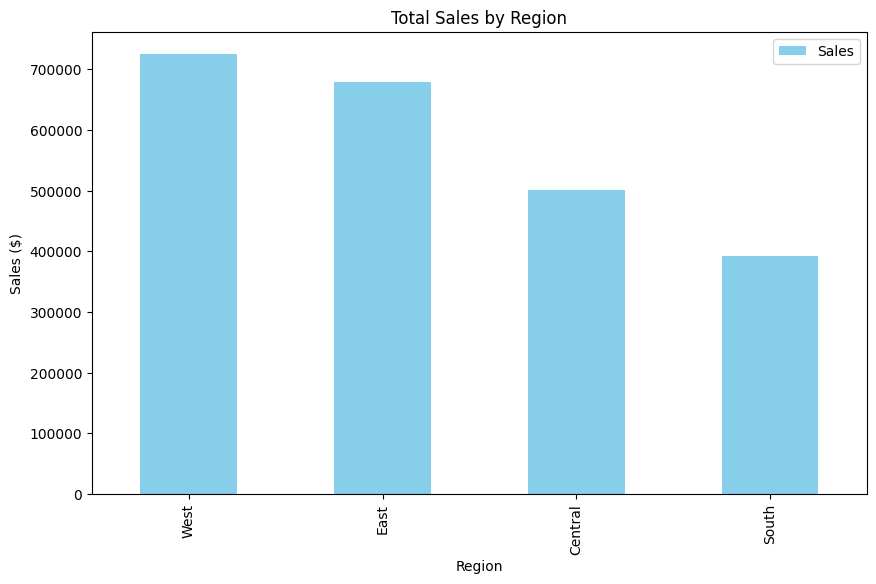

In [18]:
import matplotlib.pyplot as plt
Region_Sales.plot(kind='bar', color = 'skyblue', figsize = (10, 6))
plt.title('Total Sales by Region')
plt.ylabel('Sales ($)')
plt.show()

               Sales       Profit
Region                           
West     725457.8245  108418.4489
East     678781.2400   91522.7800
South    391721.9050   46749.4303
Central  501239.8908   39706.3625


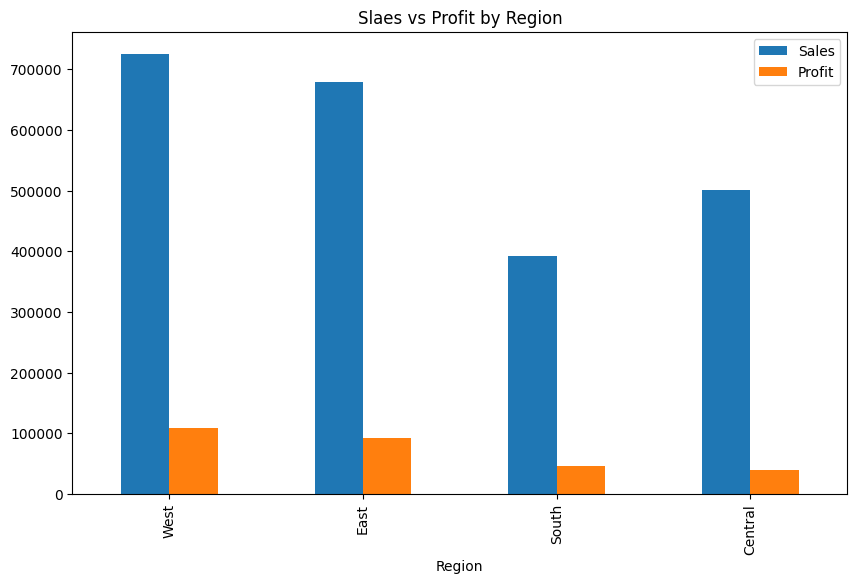

In [21]:
region_comparison = df.groupby('Region')[['Sales', 'Profit']].sum()
region_comparison= region_comparison.sort_values(by='Profit', ascending= False)
print(region_comparison)
region_comparison.plot(kind='bar', figsize = (10,6))
plt.title('Slaes vs Profit by Region')
plt.show()

In [22]:
product_losses = df.groupby('Product Name')[['Profit']].sum()
worst_products= product_losses.sort_values(by='Profit').head(10)
print('Top 10 Loss-Making Products:')
print(worst_products)

Top 10 Loss-Making Products:
                                                       Profit
Product Name                                                 
Cubify CubeX 3D Printer Double Head Print          -8879.9704
Lexmark MX611dhe Monochrome Laser Printer          -4589.9730
Cubify CubeX 3D Printer Triple Head Print          -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Table... -2876.1156
Bush Advantage Collection Racetrack Conference ... -1934.3976
GBC DocuBind P400 Electric Binding System          -1878.1662
Cisco TelePresence System EX90 Videoconferencin... -1811.0784
Martin Yale Chadless Opener Electric Letter Opener -1299.1836
Balt Solid Wood Round Tables                       -1201.0581
BoxOffice By Design Rectangular and Half-Moon M... -1148.4375


In [23]:
print('Missing values in each column:')
print(df.isnull().sum())

print('\nNumber of duplicated rows:')
print(df.duplicated().sum())

Missing values in each column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Cost             0
dtype: int64

Number of duplicated rows:
0


In [25]:
df=df.drop_duplicates()
print('\nDuplicates removed successfully!')


Duplicates removed successfully!


In [26]:
df['Cost']= df['Sales'] - df['Profit']
df['Profit_Margin_%'] = (df['Profit']/df['Sales']) * 100
df[['Product Name', 'Sales', 'Profit', 'Cost', 'Profit_Margin_%']].head()

,Product Name,Sales,Profit,Cost,Profit_Margin_%
0,Bush Somerset Collection Bookcase,261.9600,41.9136,220.0464,16.00
1,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,219.5820,512.3580,30.00
2,Self-Adhesive Address Labels for Typewriters b...,14.6200,6.8714,7.7486,47.00
3,Bretford CR4500 Series Slim Rectangular Table,957.5775,-383.0310,1340.6085,-40.00
4,Eldon Fold 'N Roll Cart System,22.3680,2.5164,19.8516,11.25


In [33]:
df.to_excel('Superstore_Python_Cleaned.xlsx', index=False)
print("File saved and ready to download!")

File saved and ready to download!


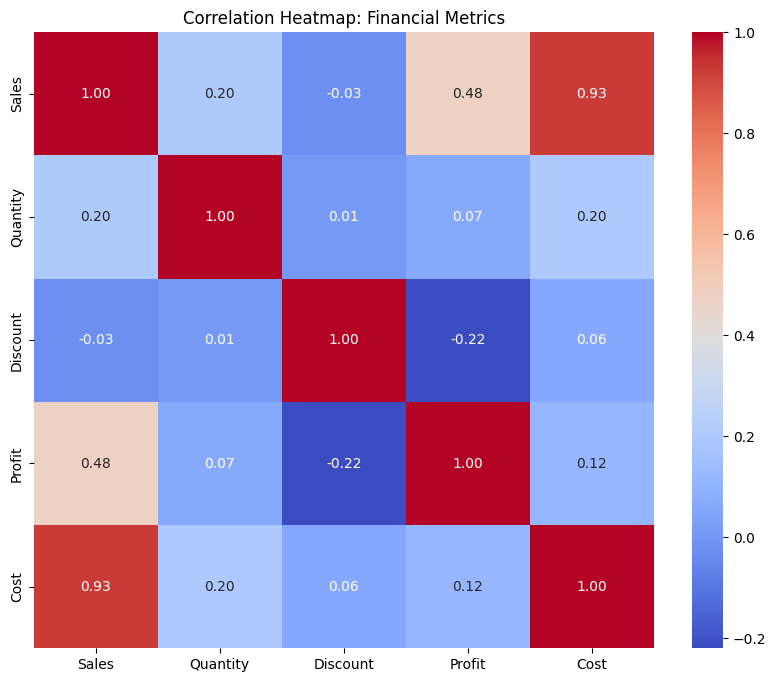

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt
numeric_df = df[['Sales','Quantity', 'Discount', 'Profit', 'Cost']]
correlation_matrix = numeric_df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap: Financial Metrics')
plt.show()

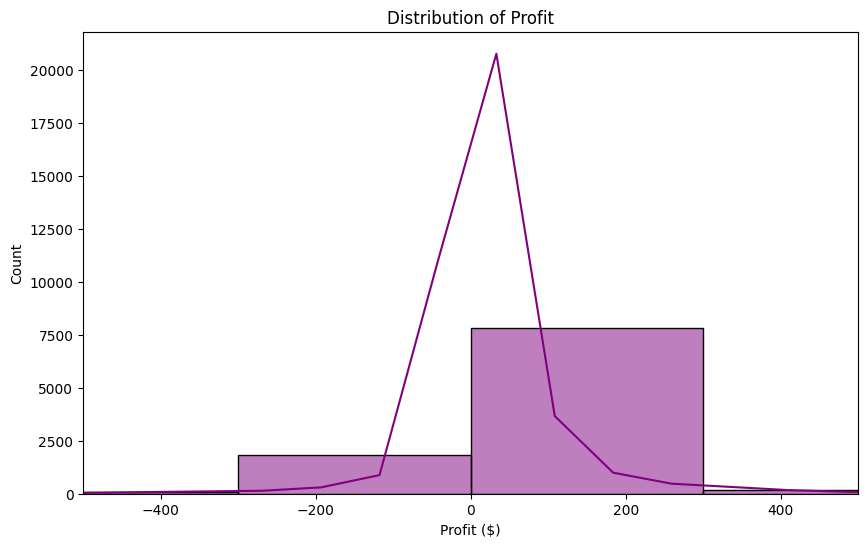

In [28]:
plt.figure(figsize=(10, 6))
sns.histplot(df['Profit'], bins=50, kde=True, color='purple')
plt.title('Distribution of Profit')
plt.xlabel('Profit ($)')
plt.xlim(-500, 500)
plt.show()

In [31]:
total_sales= df['Sales'].sum()
total_profit= df['Profit'].sum()
overall_margin= (total_profit/ total_sales) * 100
worst_sub_cat= df.groupby('Sub-Category')['Profit'].sum().idxmin()
worst_sub_val= df.groupby('Sub-Category')['Profit'].sum().min()

report_text= f"""
*** Executive Flash Report ***
------------------------------
Total Sales: ${total_sales:,.2f}
Total Profit: ${total_profit:,.2f}
Overall Profit Margin: {overall_margin:.2f}%

Critical Insight:
The most loss-making sub-category is [{worst_sub_cat}]
with a total loss of: ${worst_sub_val:,.2f}

Correlation (Profit vs Discount): -0.22 (Negative Impact)
------------------------------
"""
print(report_text)


*** Executive Flash Report ***
------------------------------
Total Sales: $2,297,200.86
Total Profit: $286,397.02
Overall Profit Margin: 12.47%

Critical Insight:
The most loss-making sub-category is [Tables] 
with a total loss of: $-17,725.48

Correlation (Profit vs Discount): -0.22 (Negative Impact)
------------------------------



In [32]:
with open("daily_report.txt", "w") as file:
    file.write(report_text)

print("Report saved as 'daily_report.txt' - Ready to be sent!")

Report saved as 'daily_report.txt' - Ready to be sent!


In [36]:
from sklearn.linear_model import LinearRegression
import numpy as np

X = df[['Discount']]
y = df['Profit']

model = LinearRegression()
model.fit(X, y)

discount_value = np.array([[0.50]])
predicted_profit = model.predict(discount_value)

print(f"If the discount is 50%, the predicted profit/loss per sale is: ${predicted_profit[0]:.2f}")

If the discount is 50%, the predicted profit/loss per sale is: $-56.97


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


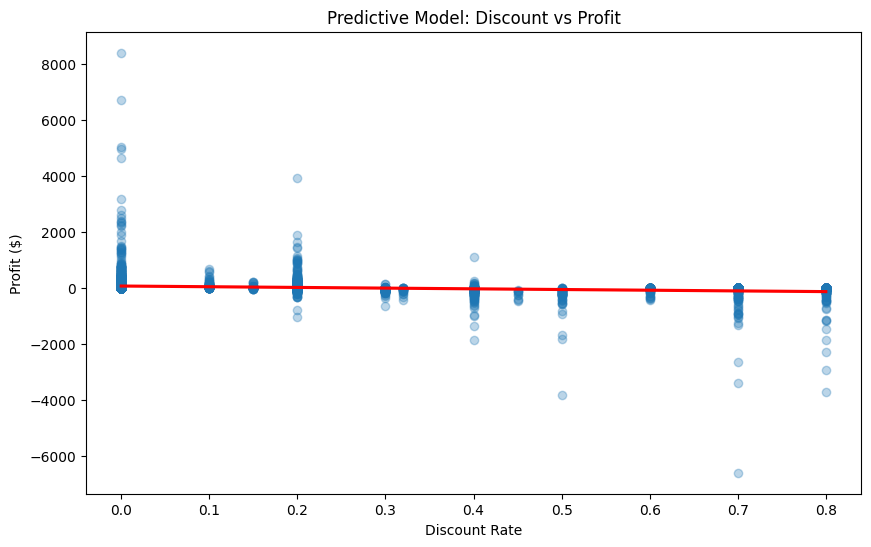

In [38]:
plt.figure(figsize=(10, 6))
sns.regplot(x='Discount', y='Profit', data=df, scatter_kws={'alpha':0.3}, line_kws={'color': 'red'})
plt.title('Predictive Model: Discount vs Profit')
plt.xlabel('Discount Rate')
plt.ylabel('Profit ($)')
plt.show()

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(



    ======= FINAL BUSINESS INTELLIGENCE REPORT =======
    - Total Cleaned Records: 9994
    - Total Company Profit: $286,397.02
    - Most Critical Loss: Tables ($-17,725.48)
    - Prediction: A 50% discount leads to an average profit of: $-56.97
    


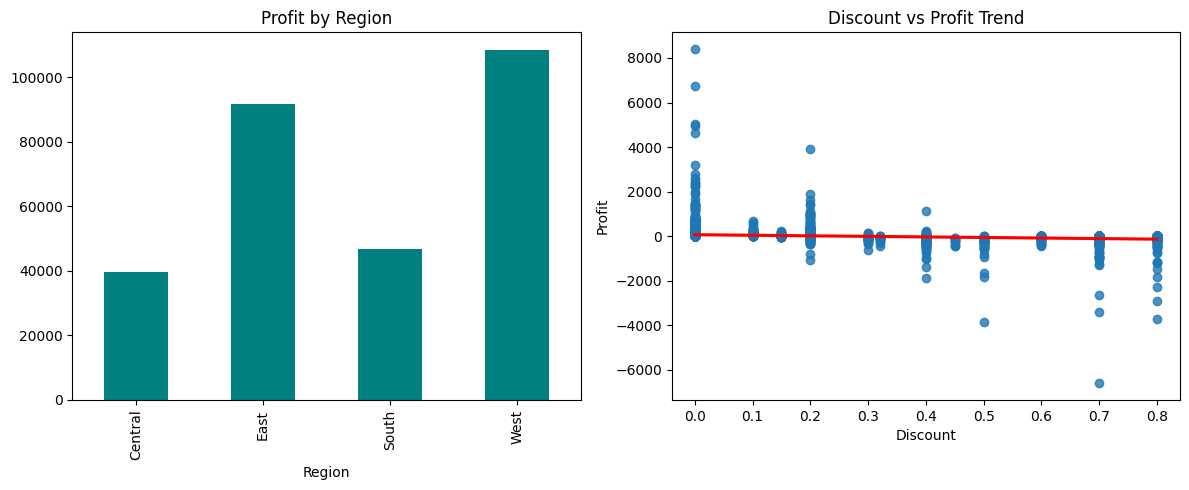

In [41]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression

def run_full_analysis(file_path):
    df = pd.read_excel(file_path)
    df = df.drop_duplicates()
    df['Cost'] = df['Sales'] - df['Profit']

    cat_analysis = df.groupby('Category')[['Sales', 'Profit']].sum()
    cat_analysis['Margin_%'] = (cat_analysis['Profit'] / cat_analysis['Sales']) * 100

    sub_cat_profit = df.groupby('Sub-Category')['Profit'].sum()
    worst_sub = sub_cat_profit.idxmin()
    worst_val = sub_cat_profit.min()

    X = df[['Discount']]
    y = df['Profit']
    model = LinearRegression().fit(X, y)
    pred_50 = model.predict([[0.5]])[0]

    report = f"""
    ======= FINAL BUSINESS INTELLIGENCE REPORT =======
    - Total Cleaned Records: {len(df)}
    - Total Company Profit: ${df['Profit'].sum():,.2f}
    - Most Critical Loss: {worst_sub} (${worst_val:,.2f})
    - Prediction: A 50% discount leads to an average profit of: ${pred_50:.2f}
    ==================================================
    """
    print(report)

    plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    df.groupby('Region')['Profit'].sum().plot(kind='bar', color='teal')
    plt.title('Profit by Region')

    plt.subplot(1, 2, 2)
    sns.regplot(x='Discount', y='Profit', data=df, line_kws={'color':'red'})
    plt.title('Discount vs Profit Trend')

    plt.tight_layout()
    plt.show()

run_full_analysis('/content/superstore1.xlsx')